# XFeat — 연속 열 분할 learned projection + float cosine (2026-10-06)

**열을 섞지 않습니다. 원래 순서에서 연속 구간으로 잘라 독립적인 projection을 적용합니다.**
각 KP(행)는 유지됩니다. 그룹 수 1·2·3·4·5·8 × 출력 32·16차원 = 12개 모델과 원본 64차원 cosine을 비교합니다.

| 그룹 수 | 입력 분할 | 출력 32 (1/2) | 출력 16 (1/4) |
|---|---|---|---|
| 1 | 64 | 32 | 16 |
| 2 | 32+32 | 16+16 | 8+8 |
| 3 | 22+21+21 | 11+11+10 | 6+5+5 |
| 4 | 16+16+16+16 | 8+8+8+8 | 4+4+4+4 |
| 5 | 13+13+13+13+12 | 7+7+6+6+6 | 4+3+3+3+3 |
| 8 | 8×8 | 4×8 | 2×8 |

나누어떨어지지 않는 차원은 앞 그룹부터 1개씩 더 배정합니다. 합계 출력 차원은 반드시 32/16입니다.

**흐름:** 원본 열 순서로 자르기 → 그룹별 bias 없는 선형 projection → 옆으로 연결 → 전체 행 L2 정규화 → float cosine 행렬곱 한 번 → 양방향 argmax → 개별 KP MNN.

**학습:** XFeat 고정. calibration 이미지의 기하학적 대응으로 projection만 학습. A/B 가중치 공유. 모든 모델에 동일한 배치 스케줄·400 steps·batch 최대128·양방향 contrastive CE 사용. 한 학습 seed의 비교이며 반복 seed 검증은 아닙니다. 열 순서와 그룹 경계는 학습 중에도 변하지 않습니다.

**실행:** 런타임 → 모두 실행. 마지막 6번에 정확도표·속도표·단계별 시간·모델 스펙·그래프를 직접 표시합니다. 가로로 잘리지 않도록 정확도와 시간 표를 분리합니다.

데이터 설정은 이전 사분면 실험과 같은 COCO split/독립 warp RNG, HPatches 24쌍입니다. 기존 ZIP을 재사용합니다. 이 파일에서는 사분면/BLOB/양자화/Thermometer를 사용하지 않습니다.

**시간:** projection·정규화 포함 total과 사전 압축 cached matching을 모두 측정. XFeat 추출·학습·정답 검사·파일 저장 제외. 출력 차원이 줄어도 KP pair 수와 점수 행렬 N×M은 유지됩니다. 작은 projection 여러 번의 호출 비용도 포함하므로 속도 향상을 보장하지 않습니다.


## 1. 데이터·환경 설정
TOP_K=800, CPU 2 threads. HPatches 생략은 RUN_HPatches=False. 모델 학습 설정은 4번 셀 상단.

In [1]:
%pip -q install opencv-python-headless pandas matplotlib threadpoolctl tqdm


import time
import io
import zipfile
import subprocess
import shutil
from pathlib import Path
import cv2
import numpy as np
import torch
import torch.nn.functional as F
from google.colab import files, drive

SEED = 7
TOP_K = 800
CALIBRATION_WARPS_PER_IMAGE = 1
VALIDATION_WARPS_PER_IMAGE = 3
GEOMETRIC_THRESHOLD = 3.0
CPU_THREADS = 2
RUN_HPatches = True
TIMING_PAIRS_PER_DATASET = 5  # evenly spaced pairs; compare every method on each pair
WARMUP = 5
REPEATS = 12
TIMING_ROUNDS = 3

torch.torch.manual_seed(SEED)
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

xfeat = torch.hub.load('verlab/accelerated_features', 'XFeat', pretrained=True, top_k=TOP_K, trust_repo=True).to(device).eval()
for parameter in xfeat.parameters():
    parameter.requires_grad_(False)
print('Device:', device)
# COCO is used for calibration and an internal synthetic-warp check.
# Compression/Blob models use calibration scenes. HPatches is reserved for external evaluation.
DATA_SOURCE = 'coco'  # change to 'upload' to use your own JPG/PNG files
COCO_SOURCE_COUNT = 24
COCO_URL = 'https://images.cocodataset.org/zips/val2017.zip'
drive.mount('/content/drive')
data_dir = Path('/content/drive/MyDrive/Colab Notebooks/CSE527_datasets')
data_dir.mkdir(parents=True, exist_ok=True)
print('Persistent dataset cache:', data_dir)

def download_archive(url, destination):
    if destination.exists() and zipfile.is_zipfile(destination):
        print('Using persistent Drive cache:', destination)
        return
    # Reuse a download from an earlier run in this same Colab session, if present.
    legacy = Path('/content/xfeat_data') / destination.name
    if legacy.exists() and zipfile.is_zipfile(legacy):
        shutil.copy2(legacy, destination)
        print('Copied previous runtime download into Drive:', destination)
        return
    print('Downloading once into Drive:', url)
    subprocess.run(['wget', '-q', '--show-progress', '-c', '-O', str(destination), url], check=True)
    if not zipfile.is_zipfile(destination):
        raise RuntimeError(f'Incomplete or invalid ZIP: {destination}. Delete it and rerun this cell.')

if DATA_SOURCE == 'coco':
    coco_zip = data_dir / 'val2017.zip'
    download_archive(COCO_URL, coco_zip)
    with zipfile.ZipFile(coco_zip) as archive:
        names = sorted(n for n in archive.namelist() if n.lower().endswith(('.jpg', '.jpeg', '.png')))
        if len(names) < COCO_SOURCE_COUNT:
            raise RuntimeError('COCO archive has fewer images than requested.')
        selected = np.random.default_rng(SEED).choice(len(names), COCO_SOURCE_COUNT, replace=False)
        image_items = [(Path(names[i]).name, archive.read(names[i])) for i in selected]
    print(f'Selected {len(image_items)} COCO images using seed {SEED}; no COCO annotations needed.')
elif DATA_SOURCE == 'upload':
    print('Upload JPG/PNG images from distinct scenes.')
    uploaded = files.upload()
    image_items = list(uploaded.items())
    if not image_items:
        raise ValueError('Upload at least one image.')
else:
    raise ValueError("DATA_SOURCE must be 'coco' or 'upload'")

def decode_and_resize(raw_bytes, maximum_side=640):
    image = cv2.imdecode(np.frombuffer(raw_bytes, np.uint8), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError('An uploaded file is not a readable JPG/PNG image.')
    height, width = image.shape[:2]
    scale = min(1.0, maximum_side / max(height, width))
    new_width = max(64, (int(width * scale) // 32) * 32)
    new_height = max(64, (int(height * scale) // 32) * 32)
    return cv2.resize(image, (new_width, new_height))

# Split by source image, before any synthetic warps or descriptor calibration.
# Upload images of distinct scenes; near-duplicate photos belong to the same split.
image_items = sorted(image_items)
images = [decode_and_resize(raw) for _, raw in image_items]
if len(images) >= 2:
    split_rng = np.random.default_rng(SEED)
    order = split_rng.permutation(len(images))
    validation_count = max(1, int(np.ceil(0.25 * len(images))))
    validation_ids = set(order[:validation_count].tolist())
    calibration_images = [im for i, im in enumerate(images) if i not in validation_ids]
    validation_images = [im for i, im in enumerate(images) if i in validation_ids]
    print('Calibration files:', [name for i, (name, _) in enumerate(image_items) if i not in validation_ids])
    print('Held-out files:', [name for i, (name, _) in enumerate(image_items) if i in validation_ids])
else:
    raise ValueError('At least two distinct source images are required.')
print('Calibration images:', len(calibration_images), 'Validation images:', len(validation_images))

Downloading: "https://github.com/verlab/accelerated_features/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://github.com/verlab/accelerated_features/raw/main/weights/xfeat.pt" to /root/.cache/torch/hub/checkpoints/xfeat.pt


100%|██████████| 5.96M/5.96M [00:00<00:00, 318MB/s]


Device: cpu
Mounted at /content/drive
Persistent dataset cache: /content/drive/MyDrive/Colab Notebooks/CSE527_datasets
Using persistent Drive cache: /content/drive/MyDrive/Colab Notebooks/CSE527_datasets/val2017.zip
Selected 24 COCO images using seed 7; no COCO annotations needed.
Calibration files: ['000000002261.jpg', '000000029675.jpg', '000000067534.jpg', '000000162858.jpg', '000000165713.jpg', '000000173008.jpg', '000000175364.jpg', '000000194506.jpg', '000000270402.jpg', '000000289343.jpg', '000000360097.jpg', '000000460841.jpg', '000000471869.jpg', '000000479596.jpg', '000000504711.jpg', '000000517832.jpg', '000000528524.jpg', '000000547383.jpg']
Held-out files: ['000000077595.jpg', '000000132544.jpg', '000000334006.jpg', '000000394559.jpg', '000000449432.jpg', '000000474039.jpg']
Calibration images: 18 Validation images: 6


## 2. 고정 XFeat로 calibration/검증 descriptor 추출
Calibration 이미지와 검증 이미지는 source 단위 분리. H는 학습 정답 생성과 정확도 평가에만 사용합니다.

In [2]:
def image_to_tensor(image):
    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    return torch.from_numpy(rgb.copy()).permute(2, 0, 1).float()[None].to(device) / 255.0

@torch.no_grad()
def extract_features(image):
    output = xfeat.detectAndCompute(image_to_tensor(image), top_k=TOP_K)[0]
    return {
        'keypoints': output['keypoints'].detach().cpu().float(),
        'descriptors': F.normalize(output['descriptors'].detach().cpu().float(), dim=-1),
    }

def make_random_homography(height, width, generator):
    center = (width / 2.0, height / 2.0)
    angle = generator.uniform(-20.0, 20.0)
    scale = generator.uniform(0.88, 1.08)
    affine = cv2.getRotationMatrix2D(center, angle, scale)
    affine[0, 2] += generator.uniform(-0.06, 0.06) * width
    affine[1, 2] += generator.uniform(-0.06, 0.06) * height
    homography = np.vstack([affine, [0., 0., 1.]]).astype(np.float32)
    homography[2, 0] = generator.uniform(-7e-5, 7e-5)
    homography[2, 1] = generator.uniform(-7e-5, 7e-5)
    return homography

def warp_image(image, homography, generator):
    height, width = image.shape[:2]
    warped = cv2.warpPerspective(image, homography, (width, height),
                                 flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    alpha = float(generator.uniform(0.82, 1.12))
    beta = float(generator.uniform(-12., 18.))
    return np.clip(warped.astype(np.float32) * alpha + beta, 0, 255).astype(np.uint8)

def project_points(points, homography):
    p = points.detach().cpu().numpy()
    p_h = np.concatenate([p, np.ones((len(p), 1), np.float32)], axis=1)
    projected = (homography @ p_h.T).T
    return torch.from_numpy((projected[:, :2] / projected[:, 2:3]).astype(np.float32))

def build_pairs(source_images,warps_per_image,generator,label):
    pairs=[]
    for image_index,image in enumerate(source_images):
        base=extract_features(image)
        for warp_index in range(warps_per_image):
            H=make_random_homography(*image.shape[:2],generator)
            warped=extract_features(warp_image(image,H,generator))
            pairs.append(dict(d1=base['descriptors'],d2=warped['descriptors'],
                k1=base['keypoints'],k2=warped['keypoints'],H=H,shape1=image.shape[:2],shape2=image.shape[:2],
                name=f'{label}_{image_index}_{warp_index}'))
    return pairs
start=time.perf_counter()
calibration_pairs=build_pairs(calibration_images,CALIBRATION_WARPS_PER_IMAGE,np.random.default_rng(SEED),'calibration')
validation_pairs=build_pairs(validation_images,VALIDATION_WARPS_PER_IMAGE,np.random.default_rng(SEED+1),'validation')
print('Extraction seconds:',time.perf_counter()-start)
print('Calibration pairs:',len(calibration_pairs),'Synthetic validation pairs:',len(validation_pairs))


Extraction seconds: 9.242038227999956
Calibration pairs: 18 Synthetic validation pairs: 18


## 3. HPatches 평가 쌍 (선택)

In [3]:
real_pairs = []
if RUN_HPatches:
    HPATCHES_URL = 'https://huggingface.co/datasets/vbalnt/hpatches/resolve/main/hpatches-sequences-release.zip'
    HPATCHES_SEQUENCES_PER_TYPE = 6  # 6 viewpoint + 6 illumination scenes
    HPATCHES_TARGETS = (2, 3)       # two real photos per sequence
    hpatches_zip = data_dir / 'hpatches-sequences-release.zip'
    download_archive(HPATCHES_URL, hpatches_zip)

    def decode_hpatches_with_scale(raw_bytes):
        original = cv2.imdecode(np.frombuffer(raw_bytes, np.uint8), cv2.IMREAD_COLOR)
        if original is None:
            raise RuntimeError('Failed to decode HPatches PPM image')
        old_h, old_w = original.shape[:2]
        resized = decode_and_resize(raw_bytes)
        new_h, new_w = resized.shape[:2]
        scale = np.diag([new_w / old_w, new_h / old_h, 1.0]).astype(np.float64)
        return resized, scale

    real_pairs = []
    with zipfile.ZipFile(hpatches_zip) as archive:
        entries = set(archive.namelist())
        folders = sorted({name.rsplit('/', 1)[0] for name in entries if name.endswith('/1.ppm')})
        for prefix in ('v_', 'i_'):
            selected_folders = [folder for folder in folders if folder.split('/')[-1].startswith(prefix)]
            if len(selected_folders) < HPATCHES_SEQUENCES_PER_TYPE:
                raise RuntimeError(f'Expected more HPatches {prefix} folders; found {len(selected_folders)}')
            for folder in selected_folders[:HPATCHES_SEQUENCES_PER_TYPE]:
                image_1, scale_1 = decode_hpatches_with_scale(archive.read(folder + '/1.ppm'))
                features_1 = extract_features(image_1)
                for target_id in HPATCHES_TARGETS:
                    image_name = f'{folder}/{target_id}.ppm'
                    h_name = f'{folder}/H_1_{target_id}'
                    if image_name not in entries or h_name not in entries:
                        raise RuntimeError(f'Missing HPatches image or homography: {folder}, {target_id}')
                    image_2, scale_2 = decode_hpatches_with_scale(archive.read(image_name))
                    features_2 = extract_features(image_2)
                    original_h = np.loadtxt(io.BytesIO(archive.read(h_name))).reshape(3, 3)
                    resized_h = scale_2 @ original_h @ np.linalg.inv(scale_1)
                    real_pairs.append({
                        'name': f'{folder.split("/")[-1]}:1->{target_id}',
                        'group': prefix, 'd1': features_1['descriptors'],
                        'd2': features_2['descriptors'],
                        'k1': features_1['keypoints'], 'k2': features_2['keypoints'],
                        'H': resized_h, 'shape1': image_1.shape[:2], 'shape2': image_2.shape[:2],
                    })
    print('HPatches real-photo pairs:', len(real_pairs), '(viewpoint and illumination)')



Using persistent Drive cache: /content/drive/MyDrive/Colab Notebooks/CSE527_datasets/hpatches-sequences-release.zip
HPatches real-photo pairs: 24 (viewpoint and illumination)


## 4. 연속 열 projection 구현·검사
그룹 밖의 성분을 변경해도 해당 출력 그룹에는 영향이 없는지 검사합니다. NumPy 추론과 PyTorch 모델 출력도 비교합니다.

In [4]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import time
import pandas as pd
from threadpoolctl import threadpool_limits,threadpool_info

GROUP_COUNTS=(1,2,3,4,5,8)
OUTPUT_DIMS=(32,16)
TRAIN_STEPS=400
TRAIN_BATCH=128
TRAIN_LR=0.003
TEMPERATURE=0.10

def balanced_sizes(total,groups):
    q,r=divmod(total,groups)
    return [q+int(i<r) for i in range(groups)]

class ContiguousProjection(nn.Module):
    def __init__(self,groups,out_dim,seed=7):
        super().__init__()
        self.groups=groups;self.out_dim=out_dim
        self.ins=balanced_sizes(64,groups);self.outs=balanced_sizes(out_dim,groups)
        self.blocks=nn.ParameterList()
        gen=torch.Generator(device='cpu').manual_seed(seed)
        for ni,no in zip(self.ins,self.outs):
            # Weight initialization mixes only within each fixed original column slice.
            q,_=torch.linalg.qr(torch.randn(ni,no,generator=gen),mode='reduced')
            self.blocks.append(nn.Parameter(q.contiguous()))
    def forward(self,x):
        z=[];start=0
        for width,w in zip(self.ins,self.blocks):
            z.append(x[:,start:start+width]@w);start+=width
        return F.normalize(torch.cat(z,dim=1),dim=1,eps=1e-8)
    def export(self):
        return [np.ascontiguousarray(w.detach().cpu().numpy().copy(),dtype=np.float32) for w in self.blocks]

def project_numpy(x,weights):
    z=np.empty((len(x),sum(w.shape[1] for w in weights)),np.float32)
    a=b=0
    for w in weights:
        ni,no=w.shape
        z[:,b:b+no]=x[:,a:a+ni]@w
        a+=ni;b+=no
    return z

def normalize_numpy(z):
    return np.ascontiguousarray(z/np.maximum(np.linalg.norm(z,axis=1,keepdims=True),np.float32(1e-8)),dtype=np.float32)

def encode_numpy(x,weights):return normalize_numpy(project_numpy(x,weights))

def array32(x):
    return np.ascontiguousarray(x.detach().cpu().numpy() if hasattr(x,'detach') else x,dtype=np.float32)

def warp_xy(k,H):
    h=np.c_[k,np.ones(len(k))]@H.T
    with np.errstate(divide='ignore',invalid='ignore'):return h[:,:2]/h[:,2:]

def prepare_training_pairs(raw_pairs):
    result=[]
    for p in raw_pairs:
        x,y=array32(p['d1']),array32(p['d2']);a,b=array32(p['k1']),array32(p['k2'])
        if not len(a) or not len(b):continue
        wa=warp_xy(a,p['H']);wb=warp_xy(b,np.linalg.inv(p['H']))
        d=np.linalg.norm(wa[:,None]-b[None,:],axis=2)
        back=np.linalg.norm(wb[:,None]-a[None,:],axis=2)
        d[~np.isfinite(d)]=np.inf;back[~np.isfinite(back)]=np.inf
        j=d.argmin(1);i=np.arange(len(a));r=back.argmin(1)
        keep=(r[j]==i)&(d[i,j]<GEOMETRIC_THRESHOLD)&(back[j,i]<GEOMETRIC_THRESHOLD)
        ii=i[keep];jj=j[keep]
        if len(ii)<8:continue
        # Copy outside inference mode: ordinary tensors usable by autograd.
        with torch.inference_mode(False):
            result.append(dict(x=torch.from_numpy(x[ii].copy()),y=torch.from_numpy(y[jj].copy()),
                               wa=torch.from_numpy(wa[ii].astype(np.float32)),b=torch.from_numpy(b[jj].copy())))
    if not result:raise RuntimeError('No calibration pairs with >=8 geometric correspondences.')
    return result

def make_schedule(pairs,steps,batch,seed):
    rng=np.random.default_rng(seed)
    return [(int(pi),rng.choice(len(pairs[int(pi)]['x']),min(batch,len(pairs[int(pi)]['x'])),replace=False))
            for pi in rng.integers(0,len(pairs),size=steps)]

def train_projections(pairs,steps=TRAIN_STEPS,batch=TRAIN_BATCH):
    schedule=make_schedule(pairs,steps,batch,SEED+100)
    models={};weights={};logs=[];spec=[]
    with threadpool_limits(limits=CPU_THREADS):
      for out_dim in OUTPUT_DIMS:
       for groups in GROUP_COUNTS:
        name=f'g{groups}_d{out_dim}'
        model=ContiguousProjection(groups,out_dim,SEED).cpu()
        opt=torch.optim.Adam(model.parameters(),lr=TRAIN_LR)
        start=time.perf_counter()
        for step,(pi,indices) in enumerate(schedule):
            p=pairs[pi];ids=torch.from_numpy(indices)
            xa,xb=p['x'][ids],p['y'][ids]
            za,zb=model(xa),model(xb)
            logits=(za@zb.T)/TEMPERATURE
            # Ignore nearby alternate geometric positives as negatives.
            near=torch.cdist(p['wa'][ids],p['b'][ids])<GEOMETRIC_THRESHOLD
            near.fill_diagonal_(False)
            logits=logits.masked_fill(near,float('-inf'))
            target=torch.arange(len(ids))
            loss=(F.cross_entropy(logits,target)+F.cross_entropy(logits.T,target))/2
            if not torch.isfinite(loss):raise RuntimeError(f'Non-finite loss: {name} step {step}')
            opt.zero_grad(set_to_none=True);loss.backward();opt.step()
            if step%50==0 or step==steps-1:
                value=float(loss.detach());logs.append(dict(method=name,step=step,loss=value))
                print(name,'step',step,'loss',round(value,4))
        seconds=time.perf_counter()-start
        model.eval();models[name]=model;weights[name]=model.export()
        params=sum(w.numel() for w in model.parameters())
        spec.append(dict(method=name,groups=groups,output_dim=out_dim,input_splits='+'.join(map(str,model.ins)),
            output_splits='+'.join(map(str,model.outs)),parameters=params,weight_bytes=params*4,
            descriptor_bytes=out_dim*4,compression_ratio=out_dim/64,training_seconds=seconds,
            projection_multiply_terms_per_KP=params))
        print('Trained',name,'seconds:',round(seconds,3))
    return models,weights,pd.DataFrame(logs),pd.DataFrame(spec)

def check_projection_implementation():
    rng=np.random.default_rng(1707);x=rng.normal(size=(17,64)).astype(np.float32)
    for g in GROUP_COUNTS:
      for d in OUTPUT_DIMS:
        model=ContiguousProjection(g,d);ws=model.export()
        assert sum(model.ins)==64 and sum(model.outs)==d
        dense=np.zeros((64,d),np.float32);a=b=0
        for w in ws:
            ni,no=w.shape;dense[a:a+ni,b:b+no]=w;a+=ni;b+=no
        raw=project_numpy(x,ws)
        np.testing.assert_allclose(raw,x@dense,rtol=2e-5,atol=2e-6)
        with torch.no_grad():expected=model(torch.from_numpy(x)).numpy()
        np.testing.assert_allclose(encode_numpy(x,ws),expected,rtol=2e-5,atol=2e-6)
        assert encode_numpy(np.empty((0,64),np.float32),ws).shape==(0,d)
        assert np.isfinite(encode_numpy(np.zeros((2,64),np.float32),ws)).all()
        # Every output group depends only on its exact, consecutive input columns.
        a=b=0
        for w in ws:
            ni,no=w.shape;changed=x.copy();changed[:,a:a+ni]+=1
            mask=np.ones(d,bool);mask[b:b+no]=False
            np.testing.assert_array_equal(project_numpy(changed,ws)[:,mask],raw[:,mask])
            a+=ni;b+=no
    print('PASS: all 12 splits, no column permutation/cross-group mixing, block-diagonal equivalence, NumPy/Torch agreement, zero/empty inputs.')
check_projection_implementation()


PASS: all 12 splits, no column permutation/cross-group mixing, block-diagonal equivalence, NumPy/Torch agreement, zero/empty inputs.


## 5. 동일 조건으로 12개 모델 학습
인접한 다른 정답 후보는 in-batch negative에서 제외합니다. 마지막 checkpoint를 사용하며 HPatches/validation으로 checkpoint를 선택하지 않습니다.

In [5]:
training_pairs=prepare_training_pairs(calibration_pairs)
print('Usable calibration pairs:',len(training_pairs),'correspondences:',sum(len(p['x']) for p in training_pairs))
train_start=time.perf_counter()
MODELS,EXPORT_WEIGHTS,TRAIN_LOG,SPECS=train_projections(training_pairs)
TRAIN_SECONDS=time.perf_counter()-train_start
print('Total projection training seconds:',round(TRAIN_SECONDS,3))
display(SPECS.round(4))


Usable calibration pairs: 18 correspondences: 5232
g1_d32 step 0 loss 1.6183
g1_d32 step 50 loss 0.298
g1_d32 step 100 loss 0.3563
g1_d32 step 150 loss 0.2374
g1_d32 step 200 loss 0.2232
g1_d32 step 250 loss 0.6895
g1_d32 step 300 loss 0.1626
g1_d32 step 350 loss 0.2426
g1_d32 step 399 loss 0.2918
Trained g1_d32 seconds: 1.918
g2_d32 step 0 loss 1.2473
g2_d32 step 50 loss 0.3428
g2_d32 step 100 loss 0.4421
g2_d32 step 150 loss 0.2895
g2_d32 step 200 loss 0.2615
g2_d32 step 250 loss 0.7646
g2_d32 step 300 loss 0.1869
g2_d32 step 350 loss 0.2532
g2_d32 step 399 loss 0.3065
Trained g2_d32 seconds: 2.323
g3_d32 step 0 loss 1.5414
g3_d32 step 50 loss 0.3594
g3_d32 step 100 loss 0.4135
g3_d32 step 150 loss 0.3072
g3_d32 step 200 loss 0.262
g3_d32 step 250 loss 0.8975
g3_d32 step 300 loss 0.2108
g3_d32 step 350 loss 0.2757
g3_d32 step 399 loss 0.334
Trained g3_d32 seconds: 4.997
g4_d32 step 0 loss 1.5875
g4_d32 step 50 loss 0.4459
g4_d32 step 100 loss 0.5394
g4_d32 step 150 loss 0.3107
g4_d32

,method,groups,output_dim,input_splits,output_splits,parameters,weight_bytes,descriptor_bytes,compression_ratio,training_seconds,projection_multiply_terms_per_KP
0,g1_d32,1,32,64,32,2048,8192,128,0.50,1.9178,2048
1,g2_d32,2,32,32+32,16+16,1024,4096,128,0.50,2.3227,1024
2,g3_d32,3,32,22+21+21,11+11+10,683,2732,128,0.50,4.9969,683
3,g4_d32,4,32,16+16+16+16,8+8+8+8,512,2048,128,0.50,1.2028,512
4,g5_d32,5,32,13+13+13+13+12,7+7+6+6+6,410,1640,128,0.50,1.2468,410
5,g8_d32,8,32,8+8+8+8+8+8+8+8,4+4+4+4+4+4+4+4,256,1024,128,0.50,1.5014,256
6,g1_d16,1,16,64,16,1024,4096,64,0.25,1.0346,1024
7,g2_d16,2,16,32+32,8+8,512,2048,64,0.25,1.0111,512
8,g3_d16,3,16,22+21+21,6+5+5,342,1368,64,0.25,1.1098,342
9,g4_d16,4,16,16+16+16+16,4+4+4+4,256,1024,64,0.25,1.1678,256


## 6. 정확도·속도·스펙 결과와 저장
모든 쌍에서 정확도 측정. 데이터셋당 5쌍에 warmup5, 3라운드×12회 timing. 같은 입력에서 방법·측정 순서를 섞습니다. 아래 셀만 재실행하면 재학습 없이 재측정 가능합니다. 새 결과 폴더에 CSV·가중치 NPZ·그래프·설정 JSON을 저장합니다.

Evaluated synthetic_validation 1 / 18
Evaluated synthetic_validation 2 / 18
Evaluated synthetic_validation 3 / 18
Evaluated synthetic_validation 4 / 18
Evaluated synthetic_validation 5 / 18
Evaluated synthetic_validation 6 / 18
Evaluated synthetic_validation 7 / 18
Evaluated synthetic_validation 8 / 18
Evaluated synthetic_validation 9 / 18
Evaluated synthetic_validation 10 / 18
Evaluated synthetic_validation 11 / 18
Evaluated synthetic_validation 12 / 18
Evaluated synthetic_validation 13 / 18
Evaluated synthetic_validation 14 / 18
Evaluated synthetic_validation 15 / 18
Evaluated synthetic_validation 16 / 18
Evaluated synthetic_validation 17 / 18
Evaluated synthetic_validation 18 / 18
Evaluated HPatches_test 1 / 24
Evaluated HPatches_test 2 / 24
Evaluated HPatches_test 3 / 24
Evaluated HPatches_test 4 / 24
Evaluated HPatches_test 5 / 24
Evaluated HPatches_test 6 / 24
Evaluated HPatches_test 7 / 24
Evaluated HPatches_test 8 / 24
Evaluated HPatches_test 9 / 24
Evaluated HPatches_test 10 /

,dataset,method,mutual,correct,precision_pct,reference_correct_keep_pct,median_px
0,synthetic_validation,float64d,8129,5613,69.0491,100.0000,1.3484
1,synthetic_validation,g1_d32,8129,5536,68.1019,96.3656,1.3792
2,synthetic_validation,g2_d32,8078,5525,68.3956,96.0983,1.3665
3,synthetic_validation,g3_d32,8053,5511,68.4341,95.9914,1.3645
4,synthetic_validation,g4_d32,8039,5490,68.2921,95.4213,1.3730
5,synthetic_validation,g5_d32,8072,5460,67.6412,95.1719,1.3954
6,synthetic_validation,g8_d32,8016,5431,67.7520,94.2811,1.3899
7,synthetic_validation,g1_d16,7998,5366,67.0918,92.3748,1.4159
8,synthetic_validation,g2_d16,7932,5239,66.0489,90.6467,1.4514
9,synthetic_validation,g3_d16,7854,5189,66.0682,89.7381,1.4396


SPEED — both image sets included, directly timed total


,dataset,method,prepare_ms,cached_match_ms,total_ms,p10_ms,p90_ms,total_speedup
0,synthetic_validation,float64d,0.0000,3.8793,3.9044,3.7685,5.2781,1.0000
1,synthetic_validation,g1_d32,0.5612,3.2142,3.8155,3.5579,4.9095,1.0233
2,synthetic_validation,g2_d32,0.6240,3.1790,3.8043,3.6451,6.3061,1.0263
3,synthetic_validation,g3_d32,0.6703,3.3370,3.8802,3.6874,5.0593,1.0062
4,synthetic_validation,g4_d32,0.6583,3.3236,3.9043,3.6878,5.7854,1.0000
5,synthetic_validation,g5_d32,0.7598,3.2379,3.9822,3.7669,4.7264,0.9805
6,synthetic_validation,g8_d32,0.8808,3.1927,4.0518,3.8681,4.4002,0.9636
7,synthetic_validation,g1_d16,0.4406,2.9715,3.2443,3.1026,3.7542,1.2035
8,synthetic_validation,g2_d16,0.4958,2.8781,3.4211,3.1285,4.0632,1.1413
9,synthetic_validation,g3_d16,0.5832,2.9677,3.4970,3.2128,4.9197,1.1165


STAGES — independently measured, medians do not necessarily sum to total


stage,dataset,method,bidirectional_argmax_ms,mnn_check_ms,normalization_ms,projection_ms,score_matmul_ms
0,HPatches_test,float64d,2.4438,0.0733,NaN,NaN,1.7670
1,HPatches_test,g1_d16,2.3501,0.0633,0.2471,0.2030,0.6937
2,HPatches_test,g1_d32,2.3565,0.0662,0.3032,0.2949,1.0029
3,HPatches_test,g2_d16,2.4198,0.0646,0.2429,0.2651,0.7327
4,HPatches_test,g2_d32,2.3839,0.0695,0.3014,0.3547,1.0154
5,HPatches_test,g3_d16,2.2886,0.0644,0.2502,0.3521,0.6660
6,HPatches_test,g3_d32,2.3704,0.0647,0.2981,0.3904,0.9965
7,HPatches_test,g4_d16,2.4186,0.0638,0.2496,0.3636,0.6676
8,HPatches_test,g4_d32,2.2654,0.0629,0.2979,0.3844,1.0265
9,HPatches_test,g5_d16,2.2825,0.0638,0.2441,0.4378,0.6591


MODEL SPECS — original descriptor: 64 float32 = 256 bytes/KP; no trainable parameters


,method,groups,output_dim,input_splits,output_splits,parameters,weight_bytes,descriptor_bytes,compression_ratio,training_seconds,projection_multiply_terms_per_KP
0,g1_d32,1,32,64,32,2048,8192,128,0.50,1.9178,2048
1,g2_d32,2,32,32+32,16+16,1024,4096,128,0.50,2.3227,1024
2,g3_d32,3,32,22+21+21,11+11+10,683,2732,128,0.50,4.9969,683
3,g4_d32,4,32,16+16+16+16,8+8+8+8,512,2048,128,0.50,1.2028,512
4,g5_d32,5,32,13+13+13+13+12,7+7+6+6+6,410,1640,128,0.50,1.2468,410
5,g8_d32,8,32,8+8+8+8+8+8+8+8,4+4+4+4+4+4+4+4,256,1024,128,0.50,1.5014,256
6,g1_d16,1,16,64,16,1024,4096,64,0.25,1.0346,1024
7,g2_d16,2,16,32+32,8+8,512,2048,64,0.25,1.0111,512
8,g3_d16,3,16,22+21+21,6+5+5,342,1368,64,0.25,1.1098,342
9,g4_d16,4,16,16+16+16+16,4+4+4+4,256,1024,64,0.25,1.1678,256


Reference retention is baseline-match survival, not true recall. All methods still compare every KP pair.
p10/p90 = median of per-pair percentiles, not confidence intervals. All CPU timing includes NumPy allocations/copies.
XFeat extraction, training, conversion to evaluation arrays, correctness checks and I/O are excluded from matching timing.


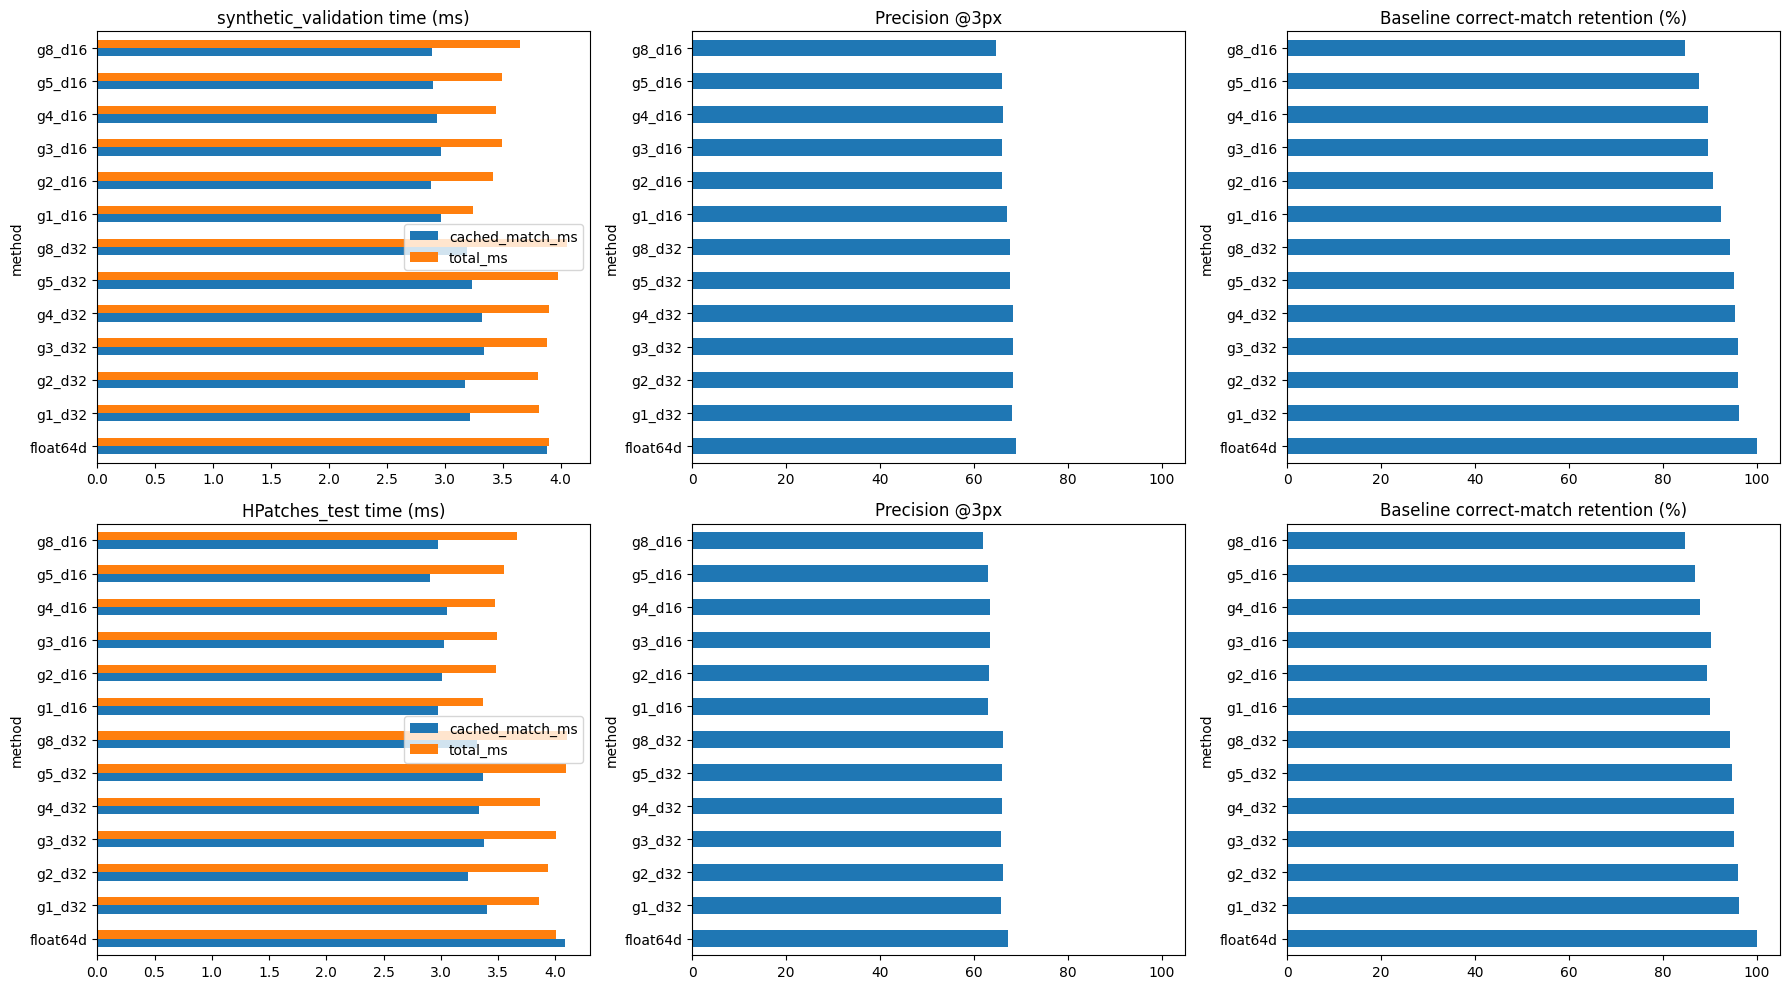

CPU: Intel(R) Xeon(R) CPU @ 2.20GHz | CPU threads: 2 | Torch: 2.11.0+cpu | NumPy: 2.1.3
RESULT FOLDER: /content/drive/MyDrive/Colab Notebooks/CSE527_datasets/experiment_results/contiguous_projection_20261006_160417_902089


In [6]:
import matplotlib.pyplot as plt
from IPython.display import display
import json,platform,os,hashlib,sys
from datetime import datetime
from zoneinfo import ZoneInfo

def pack_pair(p):
    return dict(x=array32(p['d1']),y=array32(p['d2']),k1=array32(p['k1']),k2=array32(p['k2']),
                H=np.asarray(p['H']),name=p.get('name',''))

def nn_from_scores(s):
    n,m=s.shape
    if not n or not m:return np.full(n,-1,np.int64),np.full(m,-1,np.int64)
    return s.argmax(1),s.argmax(0)

def mutual_indices(r,c):
    i=np.flatnonzero(r>=0);i=i[c[r[i]]==i]
    return i,r[i]

def cosine_mnn(a,b):return mutual_indices(*nn_from_scores(a@b.T))

def error_px(p,ij):
    i,j=ij;e=np.linalg.norm(warp_xy(p['k1'][i],p['H'])-p['k2'][j],axis=1)
    return np.where(np.isfinite(e),e,np.inf)

def prepare_pair(p,method):
    if method=='float64d':return p['x'],p['y']
    ws=EXPORT_WEIGHTS[method]
    return encode_numpy(p['x'],ws),encode_numpy(p['y'],ws)

def total_match(p,method):return cosine_mnn(*prepare_pair(p,method))

def milliseconds(fn):
    t=time.perf_counter_ns();fn();return (time.perf_counter_ns()-t)/1e6

METHODS=['float64d']+list(EXPORT_WEIGHTS)
DATASETS={'synthetic_validation':[pack_pair(p) for p in validation_pairs]}
if real_pairs:DATASETS['HPatches_test']=[pack_pair(p) for p in real_pairs]
accuracy=[];times=[];stages=[];errors={};checks=[]
with threadpool_limits(limits=CPU_THREADS):
 for dataset,pairs in DATASETS.items():
  sample=set(np.unique(np.linspace(0,len(pairs)-1,min(TIMING_PAIRS_PER_DATASET,len(pairs)),dtype=int))) if pairs else set()
  for pi,p in enumerate(pairs):
    cached={method:prepare_pair(p,method) for method in METHODS}
    matches={method:cosine_mnn(*cached[method]) for method in METHODS}
    ref=matches['float64d'];ref_e=error_px(p,ref);ref_set=set(zip(*ref))
    ref_correct=set(zip(ref[0][ref_e<GEOMETRIC_THRESHOLD],ref[1][ref_e<GEOMETRIC_THRESHOLD]))
    for method in METHODS:
        ij=matches[method];e=error_px(p,ij);ms=set(zip(*ij))
        dim=cached[method][0].shape[1]
        accuracy.append(dict(dataset=dataset,pair=pi,name=p['name'],method=method,n=len(p['x']),m=len(p['y']),
            mutual=len(e),correct=int((e<GEOMETRIC_THRESHOLD).sum()),reference_mutual=len(ref_set),
            reference_correct=len(ref_correct),retained_mnn=len(ms&ref_set),retained_correct=len(ms&ref_correct),
            output_dim=dim,descriptor_bytes=dim*4,score_matrix_bytes=len(p['x'])*len(p['y'])*4))
        errors.setdefault((dataset,method),[]).extend(e.tolist())
        for a,b in zip(ij,total_match(p,method)):np.testing.assert_array_equal(a,b)
        if method!='float64d':
            with torch.no_grad():
                tx=MODELS[method](torch.from_numpy(p['x'])).numpy()
                ty=MODELS[method](torch.from_numpy(p['y'])).numpy()
            np.testing.assert_allclose(tx,cached[method][0],atol=3e-6,rtol=3e-5)
            np.testing.assert_allclose(ty,cached[method][1],atol=3e-6,rtol=3e-5)
        checks.append(dict(dataset=dataset,pair=pi,method=method,cached_total_mnn_equal=True,torch_numpy_close=True))
    if pi in sample and len(p['x']) and len(p['y']):
        work={};parts={}
        for method in METHODS:
            a,b=cached[method];score=a@b.T;r,c=nn_from_scores(score)
            work[method]={'total_ms':lambda method=method:total_match(p,method),
                          'cached_match_ms':lambda a=a,b=b:cosine_mnn(a,b)}
            if method!='float64d':work[method]['prepare_ms']=lambda method=method:prepare_pair(p,method)
            parts[method]={'score_matmul_ms':lambda a=a,b=b:a@b.T,
                           'bidirectional_argmax_ms':lambda score=score:nn_from_scores(score),
                           'mnn_check_ms':lambda r=r,c=c:mutual_indices(r,c)}
            if method!='float64d':
                ws=EXPORT_WEIGHTS[method];rawa,rawb=project_numpy(p['x'],ws),project_numpy(p['y'],ws)
                parts[method]['projection_ms']=lambda ws=ws:(project_numpy(p['x'],ws),project_numpy(p['y'],ws))
                parts[method]['normalization_ms']=lambda rawa=rawa,rawb=rawb:(normalize_numpy(rawa),normalize_numpy(rawb))
        for _ in range(WARMUP):
            for name in METHODS:
                for fn in work[name].values():fn()
                for fn in parts[name].values():fn()
        rng_t=np.random.default_rng(SEED+pi)
        for round_id in range(TIMING_ROUNDS):
          for repeat in range(REPEATS):
            for method in rng_t.permutation(METHODS):
                vals={phase:milliseconds(work[method][phase]) for phase in rng_t.permutation(list(work[method]))}
                if method=='float64d':vals['prepare_ms']=0.0
                times.append(dict(dataset=dataset,pair=pi,method=str(method),round=round_id,repeat=repeat,**vals))
                for phase in rng_t.permutation(list(parts[method])):
                    stages.append(dict(dataset=dataset,pair=pi,method=str(method),round=round_id,repeat=repeat,
                        stage=str(phase),ms=milliseconds(parts[method][phase])))
    print('Evaluated',dataset,pi+1,'/',len(pairs))
 threadpools=threadpool_info()
accuracy_df=pd.DataFrame(accuracy);timing_raw=pd.DataFrame(times);stage_raw=pd.DataFrame(stages)
rows=[]
for (dataset,method),g in accuracy_df.groupby(['dataset','method'],sort=False):
    pct=lambda a,b:100*a/b if b else np.nan
    e=errors[dataset,method]
    rows.append(dict(dataset=dataset,method=method,mutual=int(g.mutual.sum()),correct=int(g.correct.sum()),
        precision_pct=pct(g.correct.sum(),g.mutual.sum()),median_px=float(np.median(e)) if e else np.nan,
        reference_mnn_keep_pct=pct(g.retained_mnn.sum(),g.reference_mutual.sum()),
        reference_correct_keep_pct=pct(g.retained_correct.sum(),g.reference_correct.sum())))
summary=pd.DataFrame(rows)
if len(timing_raw):
    phases=['prepare_ms','cached_match_ms','total_ms']
    pair_times=timing_raw.groupby(['dataset','pair','method'])[phases].median().reset_index()
    ts=pair_times.groupby(['dataset','method'])[phases].median().reset_index()
    spreads=timing_raw.groupby(['dataset','pair','method']).total_ms.agg(p10_ms=lambda s:s.quantile(.1),p90_ms=lambda s:s.quantile(.9))
    spreads=spreads.groupby(['dataset','method']).median().reset_index()
    summary=summary.merge(ts,on=['dataset','method']).merge(spreads,on=['dataset','method'])
    for dataset,g in summary.groupby('dataset'):
        mask=summary.dataset==dataset;b=g[g.method=='float64d'].iloc[0]
        summary.loc[mask,'total_speedup']=b.total_ms/summary.loc[mask,'total_ms']
        summary.loc[mask,'cached_speedup']=b.cached_match_ms/summary.loc[mask,'cached_match_ms']
    stage_summary=stage_raw.groupby(['dataset','pair','method','stage']).ms.median().groupby(['dataset','method','stage']).median().unstack('stage').reset_index()
else:pair_times=pd.DataFrame();stage_summary=pd.DataFrame()
# Narrow tables prevent the important total-time columns disappearing offscreen.
print('ACCURACY — final individual-KP float cosine MNN')
display(summary[['dataset','method','mutual','correct','precision_pct','reference_correct_keep_pct','median_px']].round(4))
if len(timing_raw):
    print('SPEED — both image sets included, directly timed total')
    display(summary[['dataset','method','prepare_ms','cached_match_ms','total_ms','p10_ms','p90_ms','total_speedup']].round(4))
    print('STAGES — independently measured, medians do not necessarily sum to total')
    display(stage_summary.round(4))
print('MODEL SPECS — original descriptor: 64 float32 = 256 bytes/KP; no trainable parameters')
display(SPECS.round(4))
print('Reference retention is baseline-match survival, not true recall. All methods still compare every KP pair.')
print('p10/p90 = median of per-pair percentiles, not confidence intervals. All CPU timing includes NumPy allocations/copies.')
print('XFeat extraction, training, conversion to evaluation arrays, correctness checks and I/O are excluded from matching timing.')

fig,axes=plt.subplots(len(DATASETS),3,figsize=(18,5*len(DATASETS)),squeeze=False)
for row,dataset in enumerate(DATASETS):
    g=summary[summary.dataset==dataset].set_index('method').reindex(METHODS)
    if len(timing_raw):g[['cached_match_ms','total_ms']].plot.barh(ax=axes[row,0],title=dataset+' time (ms)')
    g[['precision_pct']].plot.barh(ax=axes[row,1],title='Precision @3px',legend=False)
    g[['reference_correct_keep_pct']].plot.barh(ax=axes[row,2],title='Baseline correct-match retention (%)',legend=False)
    for col in [1,2]:axes[row,col].set_xlim(0,105)
fig.tight_layout();display(fig);plt.close(fig)

run_id=datetime.now(ZoneInfo('Asia/Seoul')).strftime('%Y%m%d_%H%M%S_%f')
result_dir=data_dir/'experiment_results'/('contiguous_projection_'+run_id);result_dir.mkdir(parents=True,exist_ok=False)
for name,df in [('summary.csv',summary),('model_specs.csv',SPECS),('training_log.csv',TRAIN_LOG),
    ('accuracy_per_pair.csv',accuracy_df),('timing_raw.csv',timing_raw),('timing_per_pair.csv',pair_times),
    ('stage_raw.csv',stage_raw),('stage_summary.csv',stage_summary),('checks.csv',pd.DataFrame(checks))]:df.to_csv(result_dir/name,index=False)
fig.savefig(result_dir/'comparison.png',dpi=160,bbox_inches='tight')
np.savez_compressed(result_dir/'projection_weights.npz',**{f'{name}_block{i}':w for name,ws in EXPORT_WEIGHTS.items() for i,w in enumerate(ws)})
cpu=platform.processor()
try:cpu=next(line.split(':',1)[1].strip() for line in open('/proc/cpuinfo') if line.startswith('model name'))
except (OSError,StopIteration):pass
report=dict(experiment='contiguous learned group projections with float cosine',column_permutation=False,
    groups=list(GROUP_COUNTS),output_dims=list(OUTPUT_DIMS),seed=SEED,training_steps=TRAIN_STEPS,batch=TRAIN_BATCH,
    learning_rate=TRAIN_LR,temperature=TEMPERATURE,train_seconds_total=TRAIN_SECONDS,
    specs=json.loads(SPECS.to_json(orient='records')),summary=json.loads(summary.to_json(orient='records')),
    cpu=cpu,cpu_threads=CPU_THREADS,logical_cpus=os.cpu_count(),platform=platform.platform(),
    versions=dict(numpy=np.__version__,torch=torch.__version__,python=sys.version),threadpools=threadpools,
    warmup=WARMUP,repeats=REPEATS,rounds=TIMING_ROUNDS,timing_pairs_per_dataset=TIMING_PAIRS_PER_DATASET,
    calibration_sources=[name for i,(name,_) in enumerate(image_items) if i not in validation_ids],
    validation_sources=[name for i,(name,_) in enumerate(image_items) if i in validation_ids],
    notes=['One training seed per configuration; no test-set tuning or best-checkpoint selection.',
           'No bias, no activation, no centering, no column permutation. Final concatenated vector is L2-normalized.',
           'Block products executed separately; loop/BLAS/copy overhead included.',
           'All N*M comparisons and full score matrix retained. Memory metric is payload, not peak RSS.'])
(result_dir/'results.json').write_text(json.dumps(report,indent=2,allow_nan=False))
print('CPU:',cpu,'| CPU threads:',CPU_THREADS,'| Torch:',torch.__version__,'| NumPy:',np.__version__)
print('RESULT FOLDER:',result_dir)
